# **Project Name** - Paisabazaar Credit Score Analysis

##### **Project Type** - EDA  
##### **Contribution** - Individual  
##### **Team Member 1 -** Manish  


# **Project Summary -**

This project explores customer information to understand how different financial and payment-related factors are connected with credit scores. The business context is Paisabazaar, a financial services company that helps people find and apply for banking and credit products. A customer's credit score is important because lenders use it while assessing creditworthiness and managing the risk of missed repayments. The aim of this analysis is to study the customer data, find patterns linked with credit score categories, and explain how those patterns may help with credit assessment and financial product recommendations.

The dataset contains 100,000 rows and 28 columns. It includes 12,500 unique customers, with eight monthly records for each customer. The information covers age, occupation, annual income, monthly salary, bank accounts, credit cards, loans, payment delays, credit inquiries, outstanding debt, credit utilisation, payment behaviour and credit score. Credit_Score is the main outcome being studied and contains three categories: Good, Standard and Poor. Since each customer appears in several months, the rows are monthly observations and should not be treated as 100,000 different people.

The analysis starts by loading the data and checking its shape, column types, duplicate rows and missing values. The initial checks show no duplicate rows and no values recorded as null. A closer look at category values finds placeholder entries that a normal missing-value check does not identify. In Payment_of_Min_Amount, the value NM is changed to Unknown. In Type_of_Loan, the exact values No Data and Not Specified are changed to Unknown. Loan combinations that contain the words Not Specified along with another loan type are kept as they also contain information. These choices are made without deleting customer records.

The numerical checks look for negative values, unusual age values and decimal values in columns that represent counts. No negative values were found in the numerical columns. The age range is 14 to 56, and 5,868 monthly records belong to 788 customers who were below 18 in at least one observed month. A customer-level check shows that 688 stayed below 18 in all eight records and 100 reached age 18 or above during the period. These records are kept because the supplied project information does not state an age eligibility rule. They are noted for further validation rather than being removed without evidence. Potentially high values are reviewed as outliers, but they are not automatically deleted or capped.

The exploratory analysis is organised into univariate, bivariate and multivariate views. Univariate charts show the distribution of credit score, age, income, salary and customer categories. Bivariate charts compare credit score with income, credit utilisation, payment delays, outstanding debt, credit history, credit mix and payment categories. The final charts examine monthly patterns and relationships among numerical variables. Matplotlib and Seaborn are used to create the charts, while Pandas and NumPy support data preparation and calculations. Google Colab is used to run the notebook.

The results are descriptive. They show patterns and differences in this dataset, but they do not prove that one factor causes a credit score to change. The analysis can help stakeholders identify payment and debt indicators worth reviewing, understand how customer groups differ, and decide where further investigation may be useful. The findings can also guide a later classification model, but building and evaluating that model is outside the EDA work completed here.

# **GitHub Link -**

# **Problem Statement**


**Problem Statement**

Explore the customer dataset and understand how financial information, credit usage and payment behaviour are related to customer credit scores. Identify data-quality issues, investigate the distribution of important variables, and use visualisations and statistical summaries to explain patterns that may support Paisabazaar's credit assessment and customer recommendations.

#### **Define Your Business Objective?**

The business objective is to understand which customer and payment characteristics show useful patterns across Good, Standard and Poor credit score categories. The analysis should help stakeholders review repayment behaviour, debt levels and credit usage when thinking about credit assessment and customer guidance. This notebook performs exploratory data analysis; it does not train or validate a credit score prediction model.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Load the libraries used in this project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Keep the charts clear and easy to read
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Show more columns when we inspect the data
pd.set_option("display.max_columns", None)


### Dataset Loading

In [ ]:
# Load the dataset

# If the CSV is already in the Colab working folder, this reads it directly.
# Otherwise, Colab will ask you to upload the CSV file.

df_raw = pd.read_csv("/content/dataset.csv")
df = df_raw.copy()
print("Dataset loaded successfully.")


Dataset loaded successfully.


### Dataset First View

In [ ]:
# Take a first look at the data

display(df.head())


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,11.27,4.0,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,4.0,11.27,4.0,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,11.27,4.0,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.0,4.0,6.27,4.0,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.0,4.0,11.27,4.0,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


### Dataset Rows & Columns count

In [ ]:
# Check the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 100000
Number of columns: 28


### Dataset Information

In [ ]:
# Check column names, non-null counts and data types

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values

In [ ]:
# Check whether any complete rows are repeated

duplicate_count = df.duplicated().sum()
print("Duplicate records:", duplicate_count)


Duplicate records: 0


#### Missing Values/Null Values

In [ ]:
# Count missing values in each column

missing_values = df.isnull().sum()
print(missing_values)
print("\nTotal missing values:", missing_values.sum())


ID                          0
Customer_ID                 0
Month                       0
Name                        0
Age                         0
SSN                         0
Occupation                  0
Annual_Income               0
Monthly_Inhand_Salary       0
Num_Bank_Accounts           0
Num_Credit_Card             0
Interest_Rate               0
Num_of_Loan                 0
Type_of_Loan                0
Delay_from_due_date         0
Num_of_Delayed_Payment      0
Changed_Credit_Limit        0
Num_Credit_Inquiries        0
Credit_Mix                  0
Outstanding_Debt            0
Credit_Utilization_Ratio    0
Credit_History_Age          0
Payment_of_Min_Amount       0
Total_EMI_per_month         0
Amount_invested_monthly     0
Payment_Behaviour           0
Monthly_Balance             0
Credit_Score                0
dtype: int64

Total missing values: 0


In [ ]:
# Show missing values as a simple chart

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if missing_counts.empty:
    print("No missing values found in the dataset.")
else:
    missing_counts.sort_values().plot(kind="barh", color="steelblue")
    plt.title("Missing Values by Column")
    plt.xlabel("Number of missing values")
    plt.ylabel("Column")
    plt.show()


No missing values found in the dataset.


### What did you know about your dataset?

The dataset has 100,000 monthly records for 12,500 customers. Each customer has eight records, covering Month 1 to Month 8. There are 28 columns containing customer identifiers, demographic details, income information, credit products, payment behaviour and the credit score category. The target column for this EDA is Credit_Score. The data contains 18 floating-point columns, three integer columns and seven object columns. The first checks found zero duplicate rows and zero null values. Placeholder text values still needed a separate review.

## ***2. Understanding Your Variables***

In [ ]:
# Display all column names

df.columns


Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [ ]:
# Summary statistics for numerical columns

df.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,100000.0,8.063150e+04,4.330149e+04,5634.000000,4.313275e+04,8.063150e+04,1.181302e+05,1.556290e+05
Customer_ID,100000.0,2.598267e+04,1.434054e+04,1006.000000,1.366450e+04,2.577700e+04,3.838500e+04,5.099900e+04
Month,100000.0,4.500000e+00,2.291299e+00,1.000000,2.750000e+00,4.500000e+00,6.250000e+00,8.000000e+00
Age,100000.0,3.331634e+01,1.076481e+01,14.000000,2.400000e+01,3.300000e+01,4.200000e+01,5.600000e+01
SSN,100000.0,5.004617e+08,2.908267e+08,81349.000000,2.451686e+08,5.006886e+08,7.560027e+08,9.999934e+08
Annual_Income,100000.0,5.050512e+04,3.829942e+04,7005.930000,1.934297e+04,3.699971e+04,7.168347e+04,1.799873e+05
Monthly_Inhand_Salary,100000.0,4.197271e+03,3.186432e+03,303.645417,1.626594e+03,3.095905e+03,5.957715e+03,1.520463e+04
Num_Bank_Accounts,100000.0,5.368820e+00,2.593314e+00,0.000000,3.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Num_Credit_Card,100000.0,5.533570e+00,2.067098e+00,0.000000,4.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Interest_Rate,100000.0,1.453208e+01,8.741330e+00,1.000000,7.000000e+00,1.300000e+01,2.000000e+01,3.400000e+01


### Variables Description

The dataset includes identifiers (ID, Customer_ID and SSN), time information (Month), demographic details (Age, Name and Occupation), income details (Annual_Income and Monthly_Inhand_Salary), credit product information (Num_Bank_Accounts, Num_Credit_Card, Num_of_Loan and Type_of_Loan), repayment information (Delay_from_due_date, Num_of_Delayed_Payment and Payment_of_Min_Amount), credit profile details (Credit_Mix, Outstanding_Debt, Credit_Utilization_Ratio and Credit_History_Age), and monthly financial behaviour (Total_EMI_per_month, Amount_invested_monthly, Payment_Behaviour and Monthly_Balance). Credit_Score contains the three score categories being studied. ID, Name and SSN identify records or people; they are not useful measures for comparing credit score patterns.

### Check Unique Values for each variable.

In [ ]:
# Count the distinct values in every column

unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Count": df.nunique().values
})

display(unique_summary)

# Show the categories in text columns.
# For columns with many values, show only the most common ones.
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    if column == "Name":
        continue

    print("\nColumn:", column)
    if df[column].nunique() <= 20:
        print(df[column].value_counts(dropna=False))
    else:
        print(df[column].value_counts(dropna=False).head(10))


,Column,Data_Type,Unique_Count
0,ID,int64,100000
1,Customer_ID,int64,12500
2,Month,int64,8
3,Name,object,10128
4,Age,float64,43
5,SSN,float64,12500
6,Occupation,object,15
7,Annual_Income,float64,12488
8,Monthly_Inhand_Salary,float64,13241
9,Num_Bank_Accounts,float64,12



Column: Occupation
Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Accountant       6744
Scientist        6744
Media_Manager    6720
Developer        6720
Teacher          6672
Entrepreneur     6648
Doctor           6568
Journalist       6536
Manager          6432
Musician         6352
Writer           6304
Name: count, dtype: int64

Column: Type_of_Loan
Type_of_Loan
No Data                    11408
Not Specified               1408
Credit-Builder Loan         1280
Personal Loan               1272
Debt Consolidation Loan     1264
Student Loan                1240
Payday Loan                 1200
Mortgage Loan               1176
Auto Loan                   1152
Home Equity Loan            1136
Name: count, dtype: int64

Column: Credit_Mix
Credit_Mix
Standard    45848
Good        30384
Bad         23768
Name: count, dtype: int64

Column: Payment_of_Min_Amount
Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype:

## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Prepare a working copy before making any changes

df = df_raw.copy()

print("Starting shape:", df.shape)
print("Duplicate records:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

# Replace placeholder entries with a clear label.
# Loan combinations that contain other loan types are left as they are.
df["Payment_of_Min_Amount"] = df["Payment_of_Min_Amount"].replace(
    "NM", "Unknown"
)

df["Type_of_Loan"] = df["Type_of_Loan"].replace({
    "No Data": "Unknown",
    "Not Specified": "Unknown"
})

print("\nPayment of minimum amount:")
print(df["Payment_of_Min_Amount"].value_counts())

print("\nMost common loan entries:")
print(df["Type_of_Loan"].value_counts().head(10))

# Check negative values in numerical columns
numerical_columns = df.select_dtypes(include="number").columns
negative_values = (df[numerical_columns] < 0).sum()
print("\nNegative values:")
print(negative_values[negative_values > 0])

# Check age values and identify customers who were below 18
print("\nAge range:", df["Age"].min(), "to", df["Age"].max())
under_18_records = df.loc[df["Age"] < 18]
under_18_customers = under_18_records["Customer_ID"].nunique()

customer_age_summary = df.groupby("Customer_ID").agg(
    min_age=("Age", "min"),
    max_age=("Age", "max"),
    record_count=("Age", "count")
)

underage_customers = customer_age_summary[
    customer_age_summary["min_age"] < 18
]
always_underage = underage_customers[
    underage_customers["max_age"] < 18
]
crossed_18 = underage_customers[
    underage_customers["max_age"] >= 18
]

print("Records below 18:", len(under_18_records))
print("Unique customers below 18:", under_18_customers)
print("Customers who stayed below 18:", len(always_underage))
print("Customers who reached 18 or above:", len(crossed_18))

# Check whether count-based columns contain decimal values
count_columns = [
    "Num_Bank_Accounts", "Num_Credit_Card", "Num_of_Loan",
    "Num_of_Delayed_Payment", "Num_Credit_Inquiries"
]

print("\nDecimal values in count-based columns:")
for column in count_columns:
    decimal_count = (df[column] % 1 != 0).sum()
    print(column, ":", decimal_count)

# Keep unusual values for investigation instead of removing them automatically.
# No age eligibility rule or outlier-removal rule was provided with the project.
print("\nFinal working shape:", df.shape)


Starting shape: (100000, 28)
Duplicate records: 0
Missing values: 0

Payment of minimum amount:
Payment_of_Min_Amount
Yes        52326
No         35667
Unknown    12007
Name: count, dtype: int64

Most common loan entries:
Type_of_Loan
Unknown                            12816
Credit-Builder Loan                 1280
Personal Loan                       1272
Debt Consolidation Loan             1264
Student Loan                        1240
Payday Loan                         1200
Mortgage Loan                       1176
Auto Loan                           1152
Home Equity Loan                    1136
Personal Loan, and Student Loan      320
Name: count, dtype: int64

Negative values:
Series([], dtype: int64)

Age range: 14.0 to 56.0
Records below 18: 5868
Unique customers below 18: 788
Customers who stayed below 18: 688
Customers who reached 18 or above: 100

Decimal values in count-based columns:
Num_Bank_Accounts : 0
Num_Credit_Card : 0
Num_of_Loan : 0
Num_of_Delayed_Payment : 0
Num_Cred

### What all manipulations have you done and insights you found?

The data was copied into a working DataFrame so the original file stays unchanged. The checks found no duplicate rows, no null values and no negative numerical values. The values NM, No Data and exact Not Specified entries were labelled Unknown because they do not provide a clear category. Loan combinations containing another loan type were kept. The age check found records for customers below 18, so these records were investigated at customer level and retained because no age rule was supplied. Count-based columns were checked for decimal values. Unusual values were not automatically deleted or capped; they should only be changed when there is a clear reason.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Credit Score Distribution

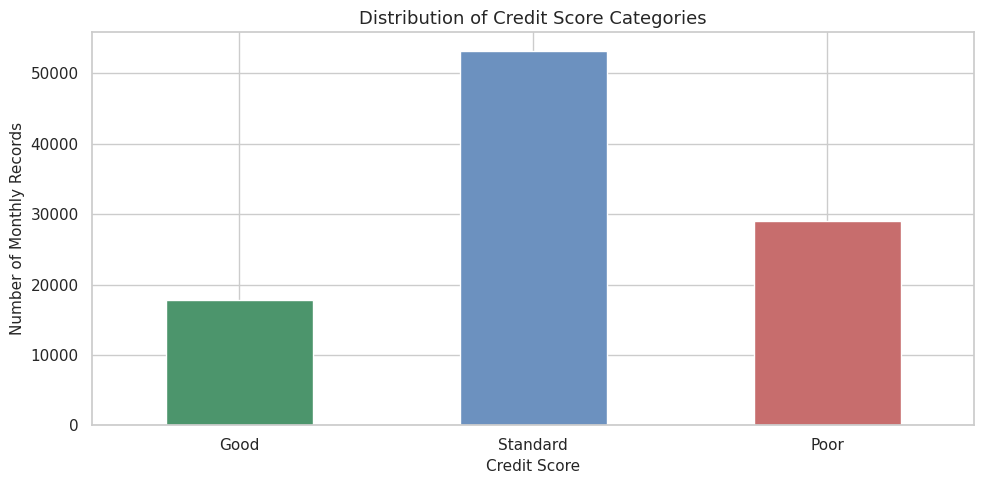

In [ ]:
score_order = ["Good", "Standard", "Poor"]
score_counts = df["Credit_Score"].value_counts().reindex(score_order)
score_counts.plot(kind="bar", color=["#4C956C", "#6C91BF", "#C76D6D"])
plt.title("Distribution of Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Number of Monthly Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare the number of records in each credit score category.

##### 2. What is/are the insight(s) found from the chart?

Standard is the largest category with 53,174 records (53.17%). Poor has 28,998 records (29.00%), and Good has 17,828 records (17.83%). The three categories are not equally represented.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Knowing the size of each score group helps the business understand the customer mix. The smaller Good category should be kept in mind when comparing groups or building a later prediction model.

#### Chart - 2 - Age Distribution

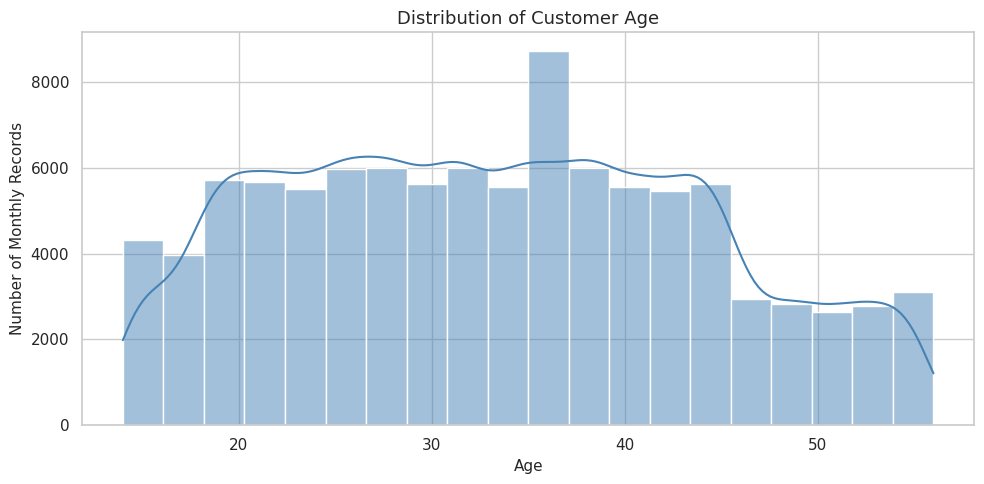

In [ ]:
sns.histplot(data=df, x="Age", bins=20, kde=True, color="steelblue")
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Monthly Records")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows how customer ages are spread and whether most records fall within a particular age range.

##### 2. What is/are the insight(s) found from the chart?

Age ranges from 14 to 56. The data is concentrated around adult age groups, while 5,868 monthly records are below age 18.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This view helps stakeholders understand the age profile represented in the data. Under-18 records should be checked against the company's eligibility rules rather than removed without evidence.

#### Chart - 3 - Annual Income Distribution

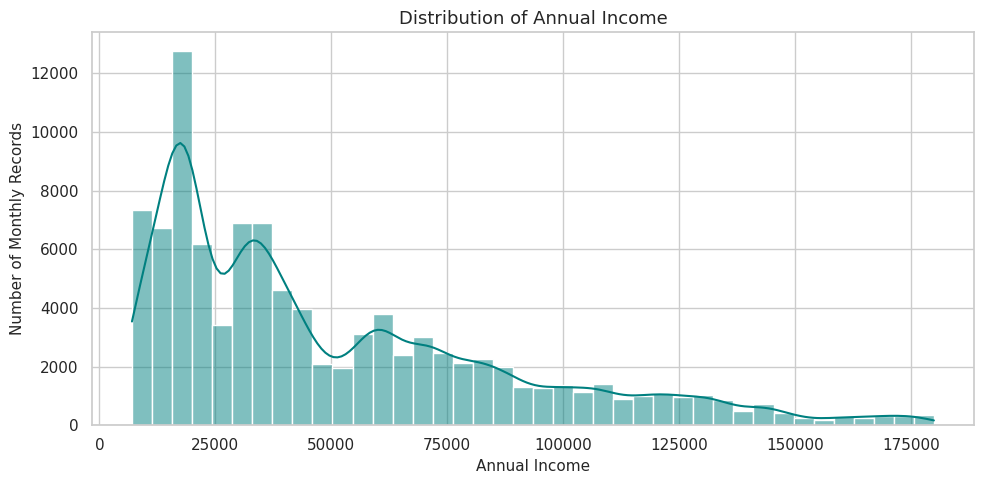

In [ ]:
sns.histplot(data=df, x="Annual_Income", bins=40, kde=True, color="teal")
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Monthly Records")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram helps show the spread of annual income and whether a small number of high values stretch the distribution.

##### 2. What is/are the insight(s) found from the chart?

Annual income has a wide range, from about 7,006 to 179,987. The mean is about 50,505 while the median is about 36,999, showing that higher income values pull the mean upward.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The income spread can help the business understand the range of customers in the dataset. Median values are useful alongside averages because the income distribution is not balanced.

#### Chart - 4 - Number of Bank Accounts Distribution

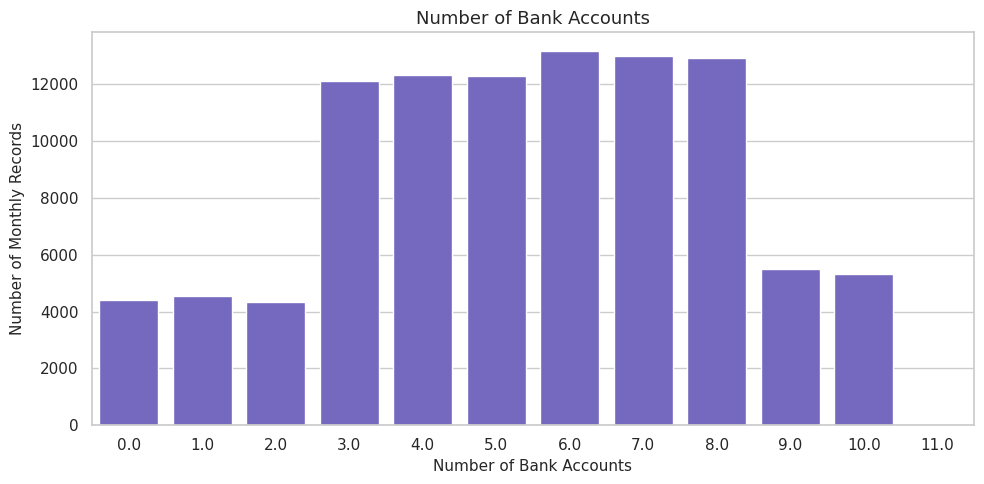

In [ ]:
sns.countplot(data=df, x="Num_Bank_Accounts", color="slateblue")
plt.title("Number of Bank Accounts")
plt.xlabel("Number of Bank Accounts")
plt.ylabel("Number of Monthly Records")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is suitable because the number of bank accounts is a count and has a limited set of whole-number values.

##### 2. What is/are the insight(s) found from the chart?

The number of bank accounts ranges from 0 to 11. The overall average is about 5.37 accounts per monthly record.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This chart gives a simple view of customers' banking relationships. The count alone does not tell us whether having more accounts leads to a better or worse credit score; that comparison is made later.

#### Chart - 5 - Credit Mix Distribution

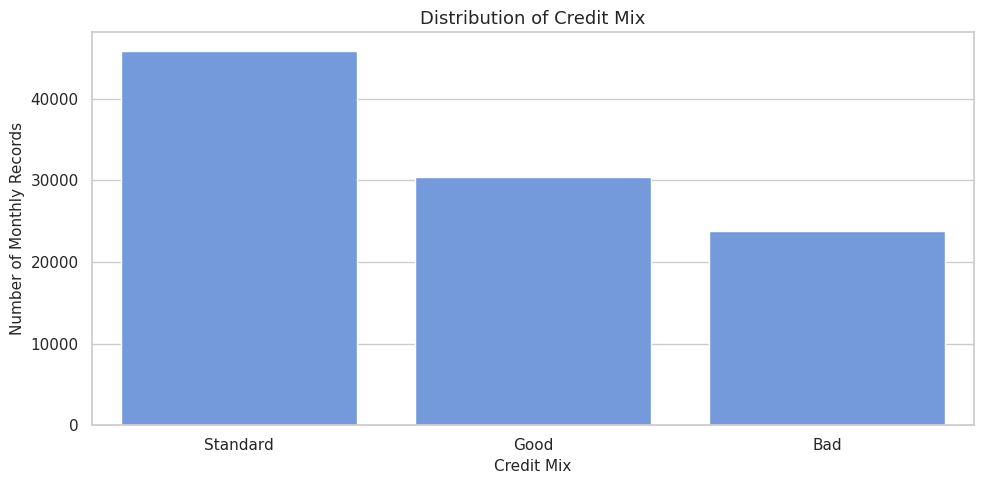

In [ ]:
sns.countplot(data=df, x="Credit_Mix", order=df["Credit_Mix"].value_counts().index, color="cornflowerblue")
plt.title("Distribution of Credit Mix")
plt.xlabel("Credit Mix")
plt.ylabel("Number of Monthly Records")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares the number of records in the three credit mix categories.

##### 2. What is/are the insight(s) found from the chart?

Standard is the most common credit mix with 45,848 records, followed by Good with 30,384 and Bad with 23,768.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The distribution helps stakeholders see how credit mix is represented. Its relationship with the actual Credit_Score is examined in a later chart, because the two columns are different measures.

#### Chart - 6 - Occupation Distribution

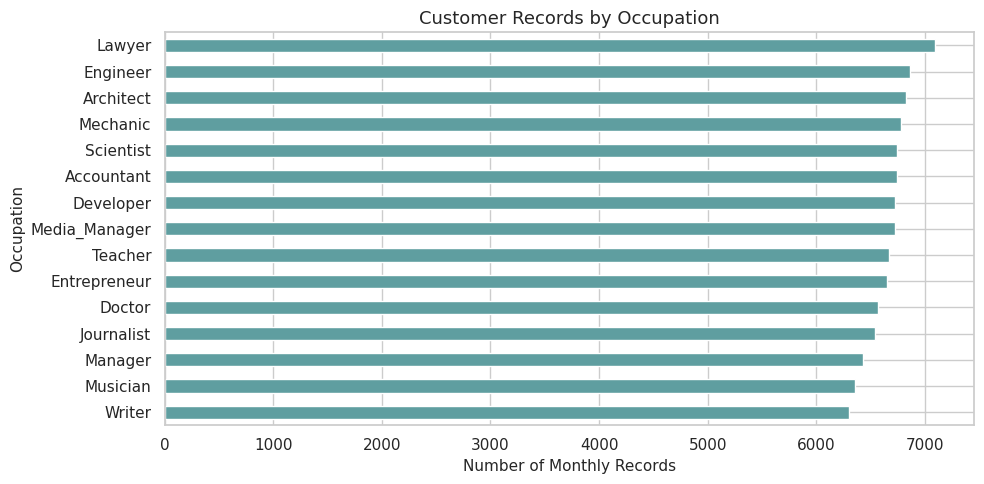

In [ ]:
occupation_counts = df["Occupation"].value_counts().sort_values()
occupation_counts.plot(kind="barh", color="cadetblue")
plt.title("Customer Records by Occupation")
plt.xlabel("Number of Monthly Records")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart makes it easier to compare all 15 occupation categories and read their names.

##### 2. What is/are the insight(s) found from the chart?

All 15 occupations have broadly similar record counts. Lawyer has the most records (7,096), while Writer has the fewest (6,304).

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The fairly even spread means no single occupation dominates the dataset. Occupation can still be compared with credit score, but differences should not be treated as proof that a job causes a particular score.

#### Chart - 7 - Payment of Minimum Amount

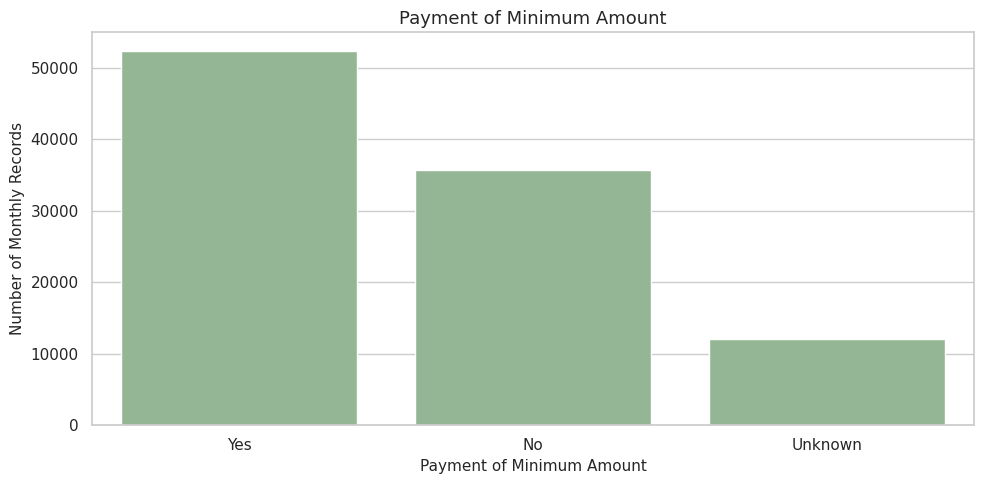

In [ ]:
payment_order = df["Payment_of_Min_Amount"].value_counts().index
sns.countplot(data=df, x="Payment_of_Min_Amount", order=payment_order, color="darkseagreen")
plt.title("Payment of Minimum Amount")
plt.xlabel("Payment of Minimum Amount")
plt.ylabel("Number of Monthly Records")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot compares the Yes, No and Unknown groups after the NM placeholder has been labelled Unknown.

##### 2. What is/are the insight(s) found from the chart?

Yes appears in 52,326 records, No in 35,667 records and Unknown in 12,007 records. Unknown represents about 12.01% of the dataset.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This helps stakeholders see how much payment information is available. The Unknown group should remain separate so it is not incorrectly treated as either Yes or No.

#### Chart - 8 - Payment Behaviour Distribution

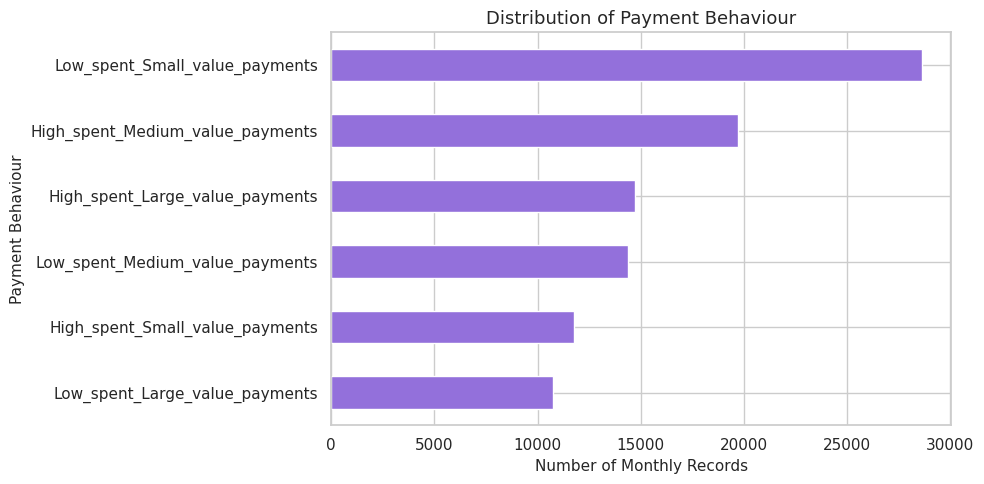

In [ ]:
behaviour_counts = df["Payment_Behaviour"].value_counts()
behaviour_counts.sort_values().plot(kind="barh", color="mediumpurple")
plt.title("Distribution of Payment Behaviour")
plt.xlabel("Number of Monthly Records")
plt.ylabel("Payment Behaviour")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart compares the six payment behaviour groups without making the labels difficult to read.

##### 2. What is/are the insight(s) found from the chart?

Low-spent, small-value payments is the largest category with 28,616 records. High-spent, large-value payments has 14,726 records.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This view gives the business a quick picture of the payment behaviour groups. The categories can be compared with credit score to see whether any group has a different score mix.

#### Chart - 9 - Age Group and Credit Score

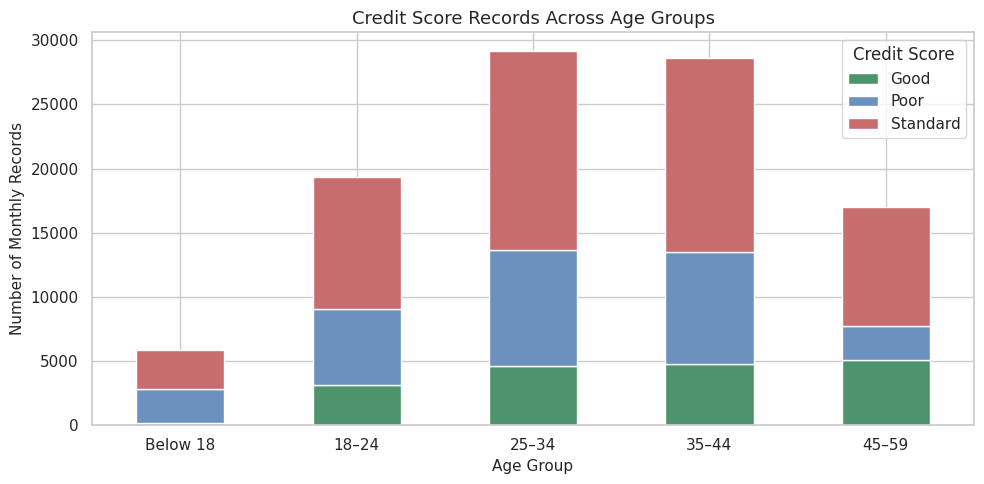

In [ ]:
age_bins = [0, 18, 25, 35, 45, 60]
age_labels = ["Below 18", "18–24", "25–34", "35–44", "45–59"]
df["Age_Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=False)
age_score_table = pd.crosstab(df["Age_Group"], df["Credit_Score"])
age_score_table.plot(kind="bar", stacked=True, color=["#4C956C", "#6C91BF", "#C76D6D"])
plt.title("Credit Score Records Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Monthly Records")
plt.xticks(rotation=0)
plt.legend(title="Credit Score")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked bar chart shows both the number of records and the score categories within each age group.

##### 2. What is/are the insight(s) found from the chart?

The 25–34 and 35–44 groups contain the most monthly records. The below-18 group is much smaller and includes records that need eligibility validation.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This helps stakeholders see the age groups represented in each score category. Age should be considered with other financial information rather than used alone.

#### Chart - 10 - Annual Income by Credit Score

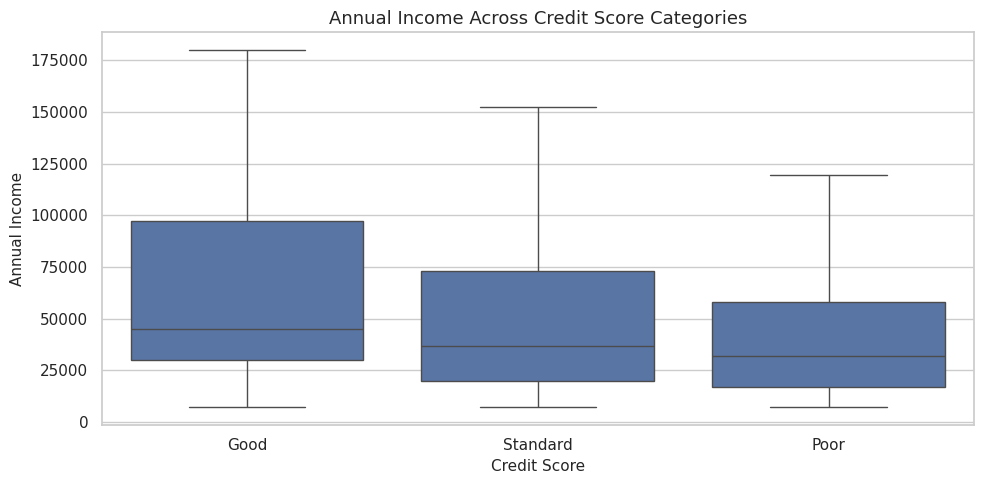

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Annual_Income", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Annual Income Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Annual Income")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot compares the median and spread of annual income across credit score groups. Outlier markers are hidden so the central spread is easier to read; the data itself is not removed.

##### 2. What is/are the insight(s) found from the chart?

The median annual income is highest in Good (about 44,928), followed by Standard (about 36,824) and Poor (about 32,065). The boxes still overlap, so income alone does not separate the groups.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This pattern can help stakeholders consider income as one part of credit assessment. It should not be used as the only basis for decisions because customers with similar incomes can have different scores.

#### Chart - 11 - Credit Utilisation by Credit Score

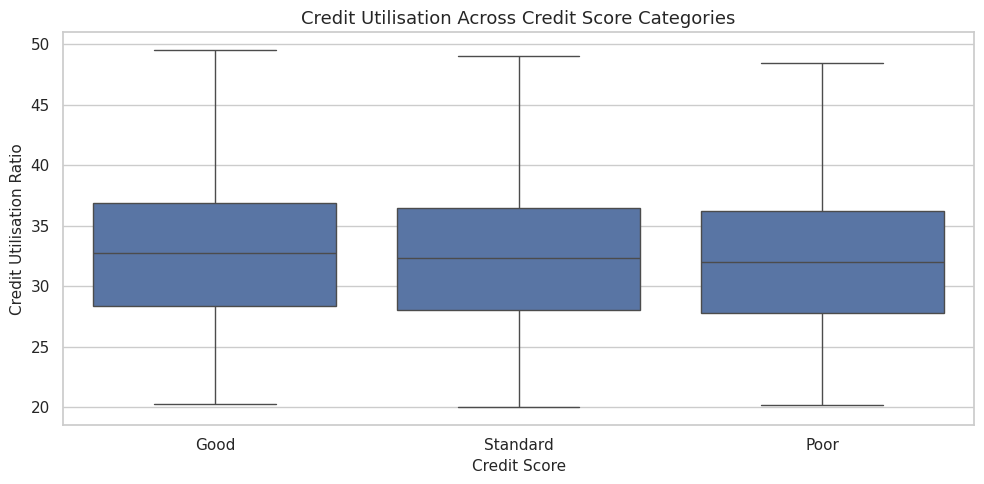

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Credit_Utilization_Ratio", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Credit Utilisation Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Credit Utilisation Ratio")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot is useful for comparing the typical credit utilisation level and spread across the three score categories.

##### 2. What is/are the insight(s) found from the chart?

The median credit utilisation ratios are close: Good is about 32.74, Standard about 32.33 and Poor about 32.01. The groups overlap considerably.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

In this dataset, credit utilisation by itself does not clearly separate credit score groups. Stakeholders should review it together with payment history and debt measures.

#### Chart - 12 - Delay from Due Date by Credit Score

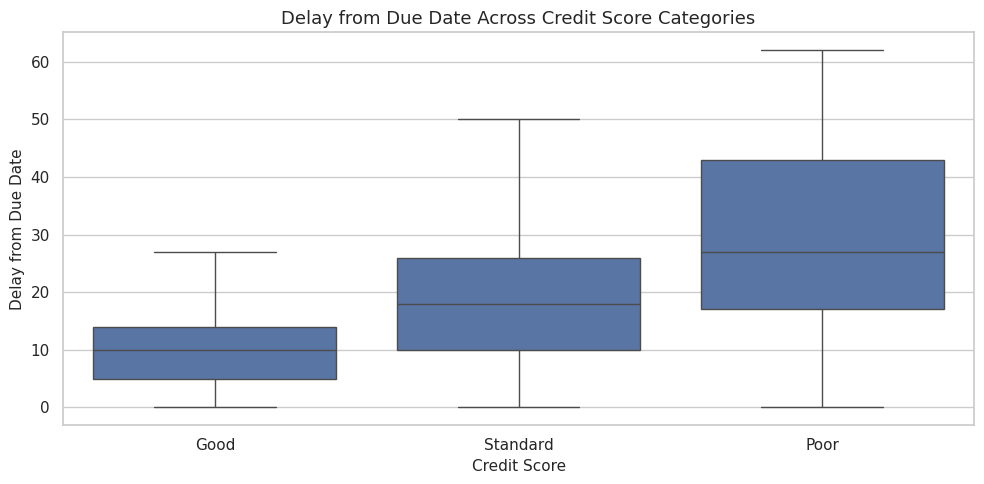

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Delay_from_due_date", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Delay from Due Date Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Delay from Due Date")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot helps compare the typical payment delay and the spread of delays across score categories.

##### 2. What is/are the insight(s) found from the chart?

The median delay is 10 for Good, 18 for Standard and 27 for Poor. The Poor group has a noticeably higher typical delay than the Good group.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This is a useful pattern for stakeholders because payment delays are closely connected with repayment behaviour. Delay information can be reviewed as part of a wider credit assessment, not as a standalone decision rule.

#### Chart - 13 - Outstanding Debt by Credit Score

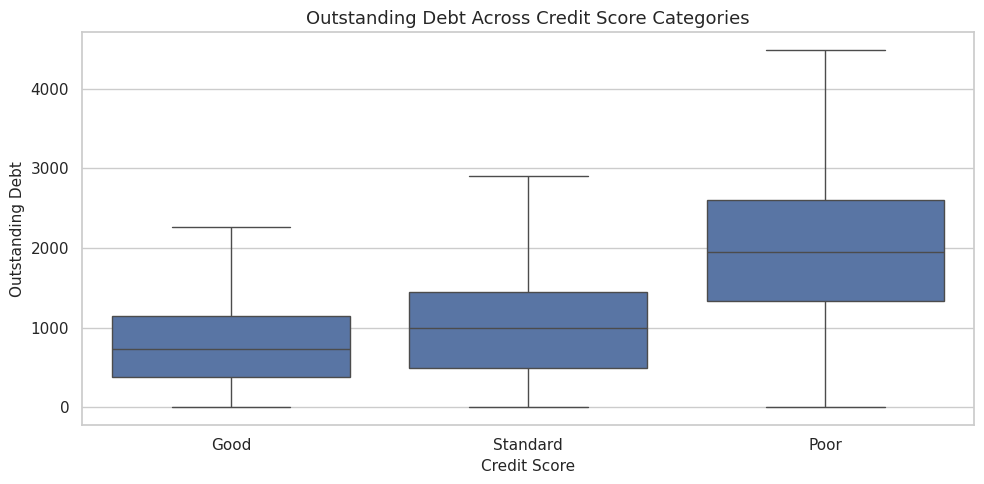

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Outstanding_Debt", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Outstanding Debt Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Outstanding Debt")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot compares the distribution of outstanding debt across credit score groups and makes differences in typical values easier to see.

##### 2. What is/are the insight(s) found from the chart?

The median outstanding debt is about 736 for Good, 1,002 for Standard and 1,945 for Poor. The Poor group has the highest median debt.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This can help stakeholders identify debt levels that deserve closer review. Debt should be considered alongside income, repayment history and other customer details.

#### Chart - 14 - Correlation Heatmap

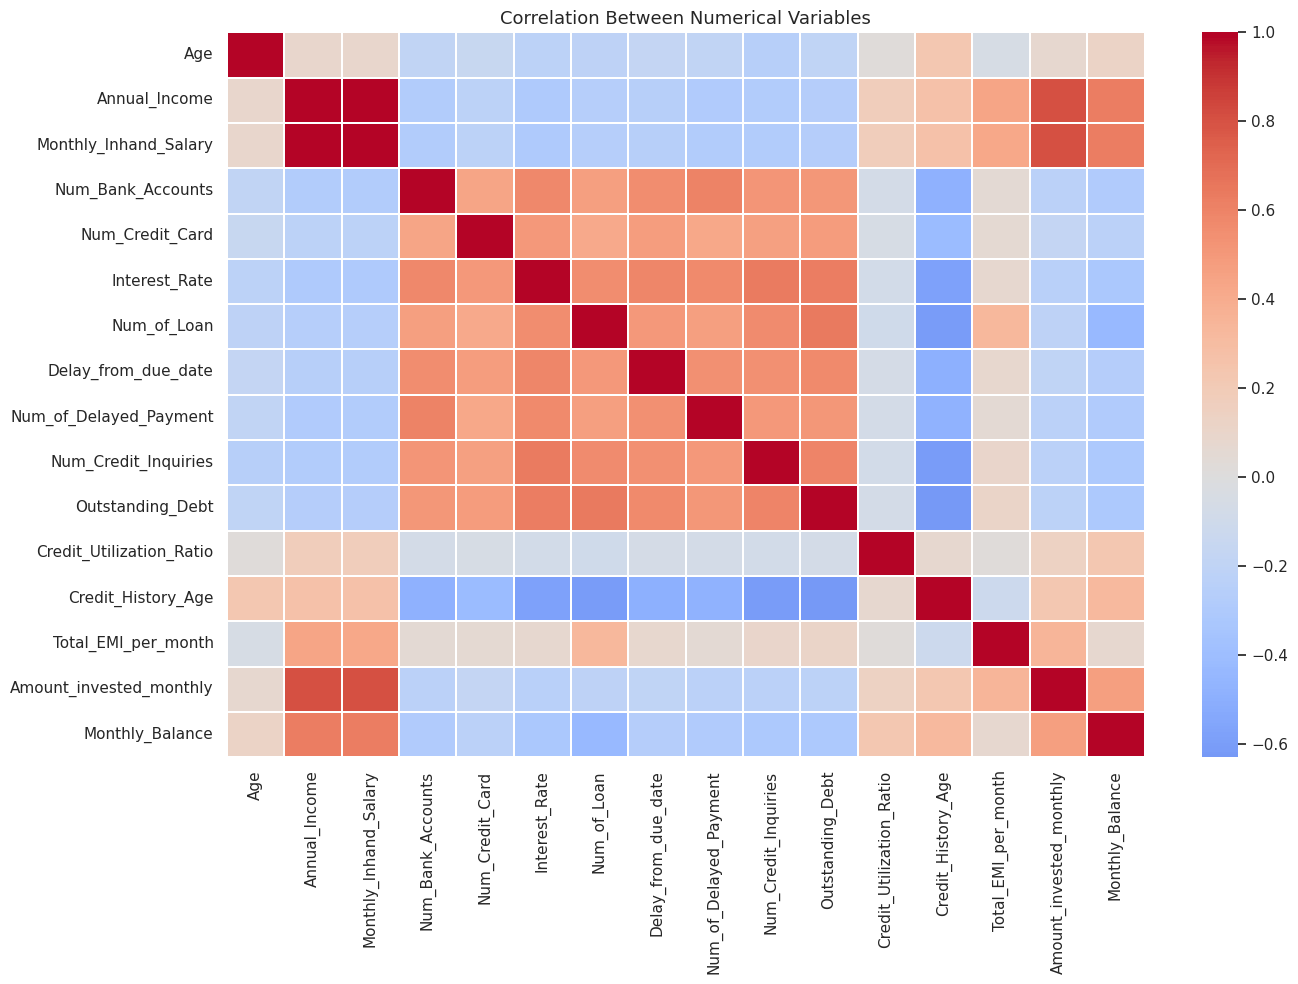

In [ ]:
correlation_columns = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary",
    "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
    "Num_of_Loan", "Delay_from_due_date",
    "Num_of_Delayed_Payment", "Num_Credit_Inquiries",
    "Outstanding_Debt", "Credit_Utilization_Ratio",
    "Credit_History_Age", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance"
]
correlation_matrix = df[correlation_columns].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap gives a single view of how numerical variables move in relation to one another. It helps identify pairs that may be worth exploring further.

##### 2. What is/are the insight(s) found from the chart?

The heatmap shows relationships among numerical columns, but correlation does not prove cause and effect. Identifier columns are left out because their numeric codes do not represent meaningful quantities.

#### Chart - 15 - Pair Plot

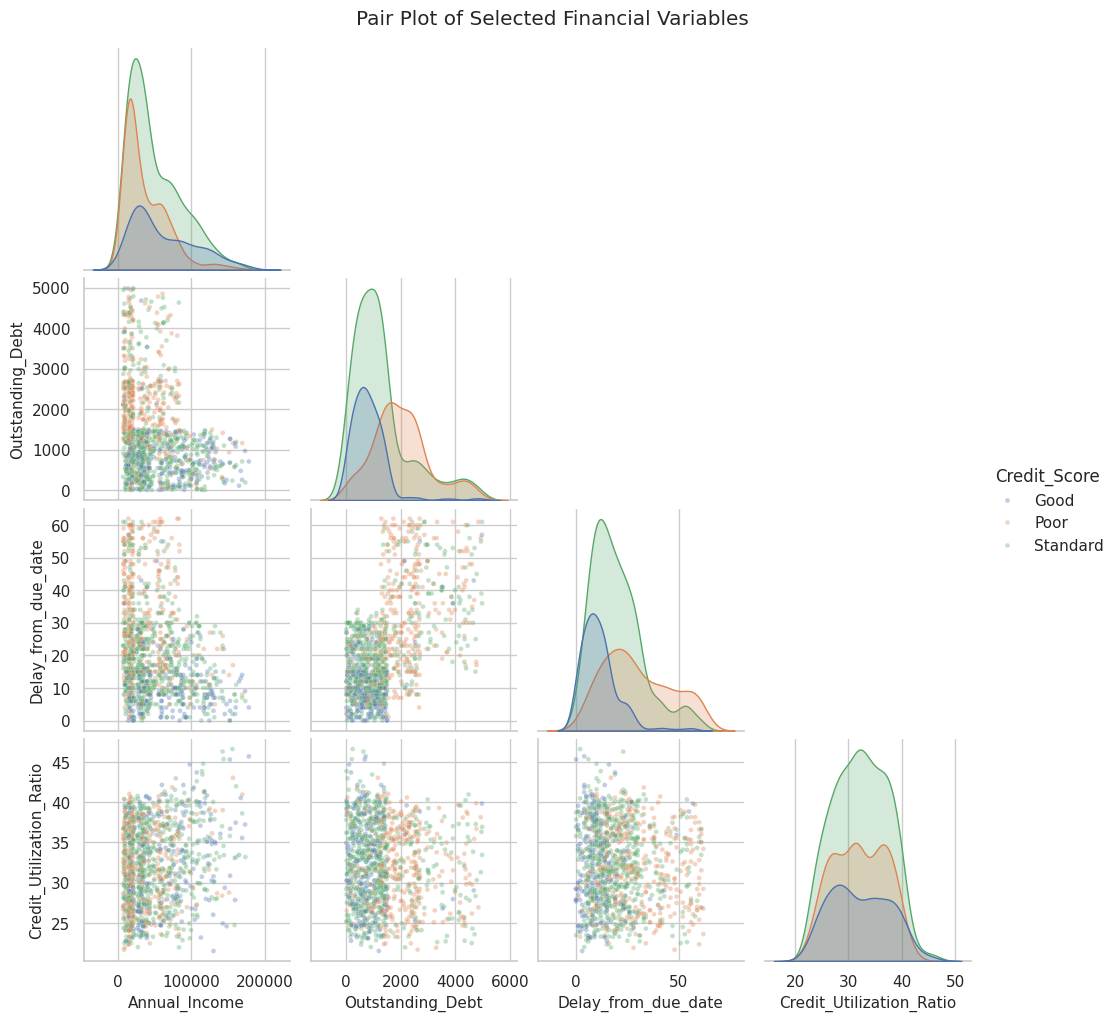

In [ ]:
pairplot_data = df[[
    "Annual_Income", "Outstanding_Debt",
    "Delay_from_due_date", "Credit_Utilization_Ratio",
    "Credit_Score"
]].sample(n=min(1200, len(df)), random_state=42)

sns.pairplot(
    pairplot_data,
    vars=["Annual_Income", "Outstanding_Debt", "Delay_from_due_date", "Credit_Utilization_Ratio"],
    hue="Credit_Score",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 12}
)
plt.suptitle("Pair Plot of Selected Financial Variables", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows several two-variable relationships together and uses colour to distinguish credit score categories. A sample is used so the chart remains readable.

##### 2. What is/are the insight(s) found from the chart?

The plots allow a visual comparison of income, debt, payment delay and credit utilisation. The score groups show clearer separation around debt and delay than around credit utilisation, although the points still overlap.

#### Chart - 16 - Credit History Age by Credit Score

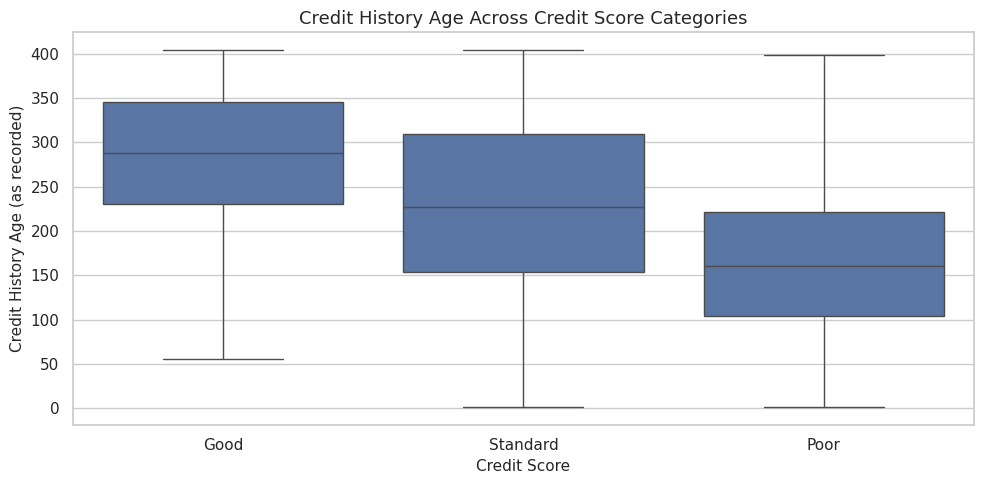

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Credit_History_Age", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Credit History Age Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Credit History Age (as recorded)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot compares the recorded credit history age across the three score categories.

##### 2. What is/are the insight(s) found from the chart?

The median recorded value is 288 for Good, 227 for Standard and 161 for Poor. The Good group has the highest median value.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This pattern suggests that the length of recorded credit history may be useful context when reviewing customers. The unit and meaning should be confirmed from the data dictionary before interpreting the values as a precise duration.

#### Chart - 17 - Number of Loans by Credit Score

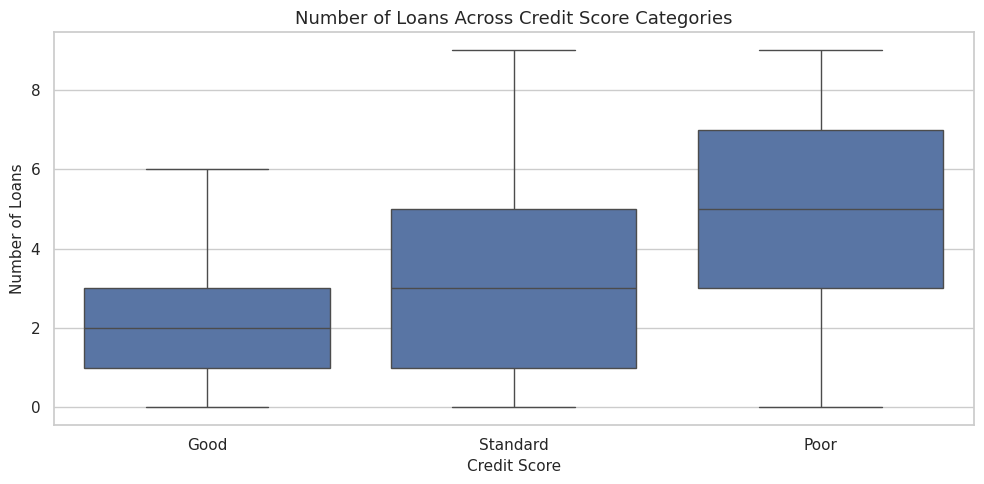

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Num_of_Loan", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Number of Loans Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot compares the typical number of loans and the spread of loan counts across credit score groups.

##### 2. What is/are the insight(s) found from the chart?

The median number of loans is 2 for Good, 3 for Standard and 5 for Poor. The Poor group tends to have more loans in this dataset.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This may help stakeholders identify customers with several active loans for a closer review. Loan count should be considered with repayment capacity and payment history.

#### Chart - 18 - Number of Credit Cards by Credit Score

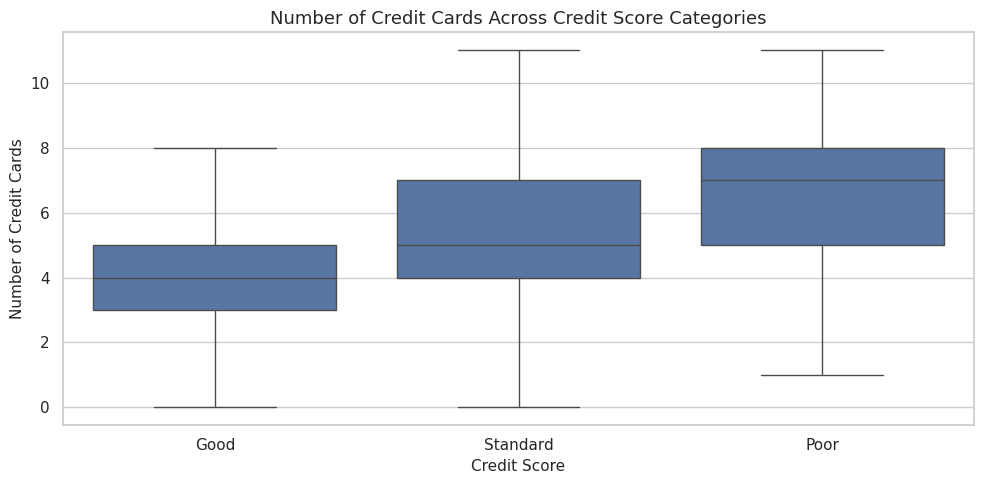

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Num_Credit_Card", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Number of Credit Cards Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Number of Credit Cards")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot makes it possible to compare the typical number of credit cards in each score category.

##### 2. What is/are the insight(s) found from the chart?

The median number of credit cards is 4 for Good, 5 for Standard and 7 for Poor. The Poor group has the highest median in this dataset.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This comparison can help stakeholders review the number of credit facilities a customer uses. It does not mean that having more cards automatically causes a poor score.

#### Chart - 19 - Number of Delayed Payments by Credit Score

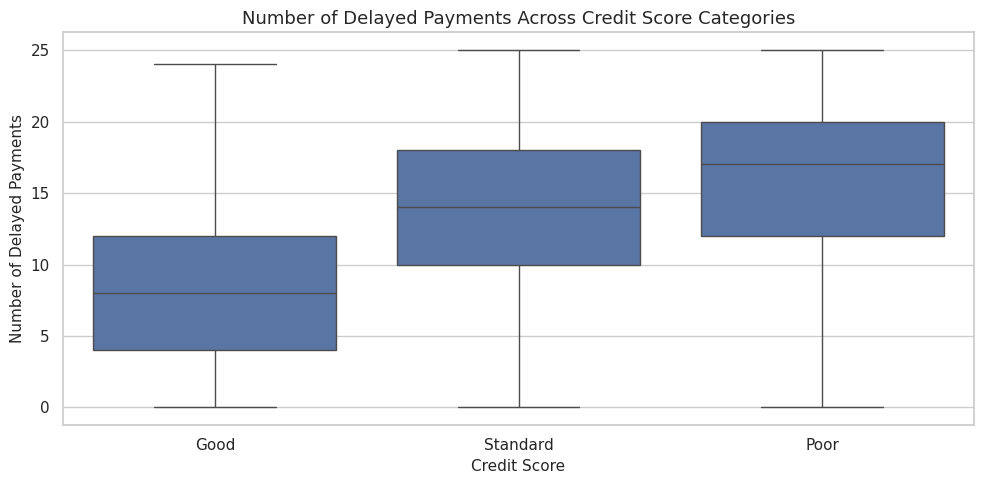

In [ ]:
sns.boxplot(data=df, x="Credit_Score", y="Num_of_Delayed_Payment", order=["Good", "Standard", "Poor"], showfliers=False)
plt.title("Number of Delayed Payments Across Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Number of Delayed Payments")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot compares the typical number of delayed payments and the spread across the three score categories.

##### 2. What is/are the insight(s) found from the chart?

The median number of delayed payments is 8 for Good, 14 for Standard and 17 for Poor. The Poor group has the highest median.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This is useful for credit risk review because missed or delayed payments are directly relevant to repayment behaviour. The measure should be checked alongside the timing and seriousness of the delays.

#### Chart - 20 - Monthly Credit Score Pattern

In [ ]:
monthly_score_share = pd.crosstab(
    df["Month"], df["Credit_Score"], normalize="index"
) * 100

monthly_score_share = monthly_score_share.reset_index().melt(
    id_vars="Month",
    var_name="Credit Score",
    value_name="Share of Monthly Records (%)"
)

fig = px.line(
    monthly_score_share,
    x="Month",
    y="Share of Monthly Records (%)",
    color="Credit Score",
    markers=True,
    title="Credit Score Category Share Across the Eight Months"
)
fig.show()

##### 1. Why did you pick the specific chart?

A line chart is suitable for showing how the share of each credit score category changes across the eight monthly periods.

##### 2. What is/are the insight(s) found from the chart?

Each month contains 12,500 records. The Good share rises from about 15.8% in Month 1 to 19.3% in Month 8, while the Standard share falls from about 55.5% to around 51.9%. The Poor share stays close to 28–30%.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This gives stakeholders a view of how the recorded score mix changes over time. Because the dataset covers only eight periods and repeats customers, the pattern should be checked further before making a business or seasonal claim.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ? Explain Briefly.

Paisabazaar can use these findings to decide which customer details deserve closer review during credit assessment. In this dataset, the Poor score group has higher median payment delays, more delayed payments, more loans, more credit cards and higher outstanding debt than the Good score group. These patterns suggest that repayment behaviour and debt commitments should be reviewed together. The Good score group also has higher median annual income and a longer recorded credit history age, although neither measure should be used alone. Credit utilisation medians are close across the three score categories, so this measure does not clearly separate the groups by itself. The Unknown payment category should be kept visible in reporting so missing or unclear information is not mistaken for a Yes or No response. The under-18 records should be checked against the company's actual eligibility policy. These findings describe associations in the supplied data; they do not prove that any one factor causes a credit score. A later prediction model would need a separate training and testing process before it could be used for decisions.

# **Conclusion**

This project explored 100,000 monthly customer records across 28 columns and 12,500 unique customers. The initial checks found no duplicate rows or null values, but the category review identified placeholder values that needed to be labelled as Unknown. The numerical checks found no negative values. The age review identified 788 customers with at least one monthly record below 18; these records were retained because the project material did not provide an eligibility rule. The visual analysis showed that Standard is the largest credit score category. It also showed clear differences in payment delays, delayed payment counts and outstanding debt across credit score groups. Median credit utilisation was similar across the three groups, so it did not provide the same separation in this dataset. Overall, the analysis shows why customer payment behaviour and debt should be reviewed alongside income and other credit details. The findings are descriptive and should be checked further before being used to make customer-level decisions.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***